[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aelkharrim/FDM5-3P/blob/main/notebooks/06_sympy.ipynb)

# Python pour la physique — 6. SymPy : les mathématiques symboliques

> 💡 **Astuce**
>
> **Rappel** : exécutez les cellules dans l'ordre avec **Maj + Entrée**. Les solutions des exercices sont masquées dans des cellules « Solution » : essayez d'abord par vous-même !



> **Objectifs**
>
>
> 1. Évaluer des expressions avec une précision arbitraire.
> 2. Effectuer des manipulations algébriques sur des expressions symboliques.
> 3. Effectuer des tâches de base de calcul différentiel et intégral (limites, dérivation, intégration) sur des expressions symboliques.
> 4. Résoudre des équations polynomiales et transcendantes.
> 5. Résoudre certaines équations différentielles.


**Qu'est-ce que SymPy ?** SymPy est une bibliothèque Python de mathématiques symboliques. Elle vise à être une alternative à des systèmes comme Mathematica ou Maple, tout en gardant un code aussi simple que possible et facilement extensible. SymPy est entièrement écrit en Python et ne nécessite aucune bibliothèque externe.

La documentation de SymPy est disponible sur <https://www.sympy.org/>.


> 📝 **Note**
>
> **Calcul symbolique ou numérique ?** Avec NumPy et SciPy, on calcule avec des **nombres** (approchés). Avec SymPy, on calcule avec des **expressions exactes** : $\sqrt{2}$ reste $\sqrt{2}$, la dérivée de $\sin x$ est $\cos x$. Les deux approches sont complémentaires : on trouve souvent une formule avec SymPy, puis on la tabule avec NumPy.

In [ ]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

# Premiers pas avec SymPy

## SymPy comme calculatrice

SymPy définit trois types numériques : `Real`, `Rational` et `Integer`.

La classe `Rational` représente un nombre rationnel comme un couple de deux entiers : le numérateur et le dénominateur. Ainsi `Rational(1, 2)` représente 1/2, `Rational(5, 2)` représente 5/2, etc. :

In [ ]:
import sympy as sym
a = sym.Rational(1, 2)

In [ ]:
a

In [ ]:
a*2

Pour que les résultats s'affichent en jolies formules mathématiques, activons l'affichage amélioré :

In [ ]:
sym.init_printing()

SymPy utilise `mpmath` en arrière-plan, ce qui permet d'effectuer des calculs en arithmétique à précision arbitraire. Ainsi, certaines constantes spéciales comme $e$, $\pi$, $\infty$ sont traitées comme des symboles et peuvent être évaluées avec une précision arbitraire :

In [ ]:
sym.pi**2

In [ ]:
sym.pi.evalf()

In [ ]:
(sym.pi + sym.exp(1)).evalf()

Comme vous le voyez, `evalf` évalue l'expression sous forme de nombre flottant.

Il existe aussi une classe représentant l'infini mathématique, appelée `oo` :

In [ ]:
sym.oo > 99999

In [ ]:
sym.oo + 1

> **Exercice**
>
> 1. Calculez $\sqrt{2}$ avec 100 décimales.
> 2. Calculez $1/2 + 1/3$ en arithmétique rationnelle.

In [1]:
import sympy as sym

# Racine de 2 avec 100 chiffres de précision
print(sym.sqrt(2).evalf(100))

# Calcul exact avec des fractions
print(sym.Rational(1, 2) + sym.Rational(1, 3))


1.414213562373095048801688724209698078569671875376948073176679737990732478462107038850387534327641573
5/6


In [ ]:
#@title Solution { display-mode: "form" }
print(sym.sqrt(2).evalf(100))
print(sym.Rational(1, 2) + sym.Rational(1, 3))

## Symboles

Contrairement à d'autres systèmes de calcul formel, avec SymPy il faut déclarer explicitement les variables symboliques :

In [ ]:
x = sym.Symbol('x')
y = sym.Symbol('y')

On peut ensuite les manipuler :

In [ ]:
x + y + x - y

In [ ]:
(x + y) ** 2

Les symboles se manipulent avec certains opérateurs Python : `+`, `-`, `*`, `**` (arithmétique), `&`, `|`, `~`, `>>`, `<<` (booléens).


> 💡 **Astuce**
>
> On peut déclarer plusieurs symboles d'un coup : `x, y, z = sym.symbols('x y z')`. En physique, on ajoute souvent des conditions, par exemple `m = sym.Symbol('m', positive=True)` pour indiquer que la masse est positive, ce qui aide SymPy à simplifier.

# Manipulations algébriques

SymPy sait effectuer de puissantes manipulations algébriques. Regardons les plus fréquentes : `expand` et `simplify`.

## Développer (`expand`)

Utilisez-le pour développer une expression algébrique :

In [ ]:
sym.expand((x + y) ** 3)

In [ ]:
3 * x * y ** 2 + 3 * y * x ** 2 + x ** 3 + y ** 3

On peut donner d'autres options sous forme de mots-clés :

In [ ]:
sym.expand(x + y, complex=True)

In [ ]:
sym.expand(sym.cos(x + y), trig=True)

## Simplifier (`simplify`)

Utilisez `simplify` pour transformer une expression en une forme plus simple :

In [ ]:
sym.simplify((x + x * y) / x)

« Simplifier » est un terme un peu vague, et il existe des alternatives plus précises : `powsimp` (simplification des exposants), `trigsimp` (expressions trigonométriques), `logcombine`, `radsimp`, `together`.

In [ ]:
sym.trigsimp(sym.sin(x)**2 + sym.cos(x)**2)

> **Exercice**
>
> 1. Calculez la forme développée de $(x+y)^6$.
> 2. Simplifiez l'expression trigonométrique $\sin(x) / \cos(x)$.

In [2]:
x, y = sym.symbols('x y')

# Développement algébrique
display(sym.expand((x + y)**6))

# Simplification trigonométrique
display(sym.trigsimp(sym.sin(x) / sym.cos(x)))


x**6 + 6*x**5*y + 15*x**4*y**2 + 20*x**3*y**3 + 15*x**2*y**4 + 6*x*y**5 + y**6

tan(x)

In [ ]:
#@title Solution { display-mode: "form" }
display(sym.expand((x + y) ** 6))
display(sym.trigsimp(sym.sin(x) / sym.cos(x)))

# Analyse

## Limites

Les limites sont faciles à utiliser dans SymPy. La syntaxe est `limit(fonction, variable, point)` : pour calculer la limite de $f(x)$ quand $x \rightarrow 0$, on écrit `limit(f, x, 0)` :

In [ ]:
sym.limit(sym.sin(x) / x, x, 0)

On peut aussi calculer des limites à l'infini :

In [ ]:
sym.limit(x, x, sym.oo)

In [ ]:
sym.limit(1 / x, x, sym.oo)

In [ ]:
sym.limit(x ** x, x, 0)

## Dérivation

On peut dériver n'importe quelle expression SymPy avec `diff(fonction, variable)`. Exemples :

In [ ]:
sym.diff(sym.sin(x), x)

In [ ]:
sym.diff(sym.sin(2 * x), x)

In [ ]:
sym.diff(sym.tan(x), x)

On peut vérifier que c'est correct avec la définition de la dérivée :

In [ ]:
sym.limit((sym.tan(x + y) - sym.tan(x)) / y, y, 0)

Ce qui est équivalent puisque

$$
\sec(x) = \frac{1}{\cos(x)} \quad\text{et}\quad \sec^2(x) = \tan^2(x) + 1.
$$

On peut le vérifier aussi :

In [ ]:
sym.trigsimp(sym.diff(sym.tan(x), x))

Les dérivées d'ordre supérieur se calculent avec `diff(fonction, variable, n)` :

In [ ]:
sym.diff(sym.sin(2 * x), x, 1)

In [ ]:
sym.diff(sym.sin(2 * x), x, 2)

In [ ]:
sym.diff(sym.sin(2 * x), x, 3)

## Développement en série

SymPy sait aussi calculer le développement de Taylor d'une expression en un point. Utilisez `series(expr, var)` :

In [ ]:
sym.series(sym.cos(x), x)

In [ ]:
sym.series(1/sym.cos(x), x)

> **Exemple physique : le pendule aux petits angles**
>
> Pourquoi remplace-t-on $\sin\theta$ par $\theta$ pour un pendule ? Regardons le développement en série de $\sin\theta$, et la **correction relative** commise :

In [ ]:
theta = sym.Symbol('theta')
sym.series(sym.sin(theta), theta, 0, 6)

In [ ]:
erreur = sym.series((theta - sym.sin(theta)) / sym.sin(theta), theta, 0, 4)
erreur

L'erreur relative vaut environ $\theta^2/6$ : pour $\theta = 0{,}1$ rad (≈ 6°), elle est de l'ordre de 0,2 %.


> **Exercice**
>
> 1. Calculez $\lim_{x\rightarrow 0} \sin(x)/x$.
> 2. Calculez la dérivée de $\ln(x)$ par rapport à $x$.

In [3]:
# Calcul de la limite
display(sym.limit(sym.sin(x) / x, x, 0))

# Dérivée du logarithme
display(sym.diff(sym.log(x), x))


1

1/x

In [ ]:
#@title Solution { display-mode: "form" }
display(sym.limit(sym.sin(x) / x, x, 0))
display(sym.diff(sym.log(x), x))

## Intégration

SymPy sait calculer des intégrales indéfinies et définies de fonctions élémentaires transcendantes et de fonctions spéciales, grâce à la fonction `integrate()`, qui utilise l'algorithme de Risch-Norman étendu ainsi que des heuristiques et de la reconnaissance de motifs. On peut intégrer des fonctions élémentaires :

In [ ]:
sym.integrate(6 * x ** 5, x)

In [ ]:
sym.integrate(sym.sin(x), x)

In [ ]:
sym.integrate(sym.log(x), x)

In [ ]:
sym.integrate(2 * x + sym.sinh(x), x)

Les fonctions spéciales sont aussi gérées facilement :

In [ ]:
sym.integrate(sym.exp(-x ** 2) * sym.erf(x), x)

On peut calculer des intégrales définies :

In [ ]:
sym.integrate(x**3, (x, -1, 1))

In [ ]:
sym.integrate(sym.sin(x), (x, 0, sym.pi / 2))

In [ ]:
sym.integrate(sym.cos(x), (x, -sym.pi / 2, sym.pi / 2))

Les intégrales impropres sont aussi gérées :

In [ ]:
sym.integrate(sym.exp(-x), (x, 0, sym.oo))

In [ ]:
sym.integrate(sym.exp(-x ** 2), (x, -sym.oo, sym.oo))

> **Exemple physique : travail et énergie**
>
> Le travail d'une force de rappel $F = -kx$ entre $0$ et $x_0$ est $W = \int_0^{x_0} (-k x)\,dx$. L'énergie potentielle élastique en est l'opposé. Avec des symboles :

In [ ]:
k, x0 = sym.symbols('k x_0', positive=True)
W = sym.integrate(-k * x, (x, 0, x0))
W

In [ ]:
Ep = -W
Ep

# Résolution d'équations

SymPy peut résoudre des équations algébriques, à une ou plusieurs variables, avec `solveset` :

In [ ]:
sym.solveset(x ** 4 - 1, x)

Comme vous le voyez, le premier argument est une expression censée être égale à 0. La fonction gère aussi (de façon limitée) les équations transcendantes :

In [ ]:
sym.solveset(sym.exp(x) + 1, x)

> **Systèmes d'équations linéaires**
>
> SymPy sait résoudre une grande partie des équations polynomiales, et aussi plusieurs équations par rapport à plusieurs variables, en donnant un tuple en second argument. Pour cela, on utilise la commande `solve` :
>

In [ ]:
solution = sym.solve((x + 5 * y - 2, -3 * x + 6 * y - 15), (x, y))
solution[x], solution[y]

Une autre possibilité pour les équations polynomiales est `factor`, qui renvoie le polynôme factorisé en termes irréductibles, et sait calculer la factorisation sur divers domaines :

In [ ]:
f = x ** 4 - 3 * x ** 2 + 1
sym.factor(f)

In [ ]:
sym.factor(f, modulus=5)

SymPy peut aussi résoudre des équations booléennes, c'est-à-dire décider si une expression booléenne est satisfiable ou non, avec la fonction `satisfiable` :

In [ ]:
sym.satisfiable(x & y)

Cela nous dit que `(x & y)` est vraie quand `x` et `y` sont toutes deux vraies. Si une expression ne peut jamais être vraie, la fonction renvoie `False` :

In [ ]:
sym.satisfiable(x & ~x)

> **Exemple physique : résoudre pour une grandeur inconnue**
>
> On connaît la loi horaire $x(t) = x_0 + v_0 t + \tfrac12 a t^2$. À quel instant le mobile atteint-il la position $x_f$ ? Avec SymPy, on obtient les deux solutions symboliques :

In [ ]:
t, x0, v0, a, xf = sym.symbols('t x_0 v_0 a x_f')
solutions = sym.solve(sym.Eq(x0 + v0*t + a*t**2/2, xf), t)
solutions

> **Exercice**
>
> 1. Résolvez le système d'équations $x + y = 2$, $2x + y = 0$.
> 2. Existe-t-il des valeurs booléennes `x`, `y` qui rendent `(~x | y) & (~y | x)` vraie ?

In [4]:
x, y = sym.symbols('x y')

# Résolution du système
solution = sym.solve(
    (x + y - 2, 2*x + y),
    (x, y)
)

print("Solution du système :", solution)

# Vérification de l'expression logique
expression = (~x | y) & (~y | x)

print("Solution booléenne :",
      sym.satisfiable(expression))


Solution du système : {x: -2, y: 4}
Solution booléenne : {x: False, y: False}


In [ ]:
#@title Solution { display-mode: "form" }
x, y = sym.symbols('x y')
print(sym.solve((x + y - 2, 2*x + y), (x, y)))
print(sym.satisfiable((~x | y) & (~y | x)))   # oui : x = y

# Algèbre linéaire

## Matrices

Les matrices sont créées comme des instances de la classe `Matrix` :

In [ ]:
sym.Matrix([[1, 0], [0, 1]])

Contrairement à un tableau NumPy, on peut aussi y mettre des symboles :

In [ ]:
x, y = sym.symbols('x, y')
A = sym.Matrix([[1, x], [y, 1]])
A

In [ ]:
A**2

On calcule de la même façon déterminants, inverses, valeurs propres :

In [ ]:
A.det(), A.inv(), A.eigenvals()

> **Exemple physique : modes propres de deux oscillateurs couplés (version exacte)**
>
> Nous avions calculé numériquement ces modes avec SciPy (carnet 5). Avec SymPy, on obtient les **formules exactes** :

In [ ]:
m, k, kc = sym.symbols('m k k_c', positive=True)
K = sym.Matrix([[k + kc, -kc],
                [-kc, k + kc]])
K.eigenvects()

Les valeurs propres de $K$ sont $k$ et $k + 2k_c$, donc les pulsations propres sont $\omega_1 = \sqrt{k/m}$ et $\omega_2 = \sqrt{(k+2k_c)/m}$.

# Équations différentielles

SymPy sait résoudre (certaines) équations différentielles ordinaires. On utilise `dsolve`. Il faut d'abord créer une fonction indéfinie en passant `cls=Function` à la fonction `symbols` :

In [ ]:
x = sym.Symbol('x')
f, g = sym.symbols('f g', cls=sym.Function)

`f` et `g` sont maintenant des fonctions indéfinies. On peut appeler `f(x)`, qui représente une fonction inconnue :

In [ ]:
f(x)

In [ ]:
f(x).diff(x, x) + f(x)

In [ ]:
sym.dsolve(f(x).diff(x, x) + f(x), f(x))

On retrouve la solution de l'oscillateur harmonique : $f(x) = C_1 \sin x + C_2 \cos x$.

On peut donner des mots-clés à cette fonction pour l'aider à trouver la meilleure méthode de résolution. Par exemple, si l'on sait que c'est une équation à variables séparables, on peut utiliser `hint='separable'` :

In [ ]:
sym.dsolve(sym.sin(x) * sym.cos(f(x)) + sym.cos(x) * sym.sin(f(x)) * f(x).diff(x), f(x), hint='separable')

> **Exemple physique : l'oscillateur harmonique amorti**
>
> Résolvons $m\ddot{x} + \alpha\dot{x} + kx = 0$ avec les conditions initiales $x(0) = x_0$, $\dot{x}(0) = 0$. Pour que SymPy trouve une solution simple, prenons le cas numérique $m = 1$, $\alpha = 2$, $k = 5$ (régime pseudo-périodique) :

In [ ]:
t = sym.Symbol('t')
x = sym.Function('x')
equation = sym.Eq(x(t).diff(t, 2) + 2 * x(t).diff(t) + 5 * x(t), 0)

solution = sym.dsolve(equation, x(t), ics={x(0): 1, x(t).diff(t).subs(t, 0): 0})
solution

On obtient une exponentielle décroissante multipliée par une oscillation de pulsation 2 rad/s ($\omega = \sqrt{k/m - (\alpha/2m)^2} = 2$).


> **Exercice**
>
> 1. Résolvez l'équation différentielle de Bernoulli
>
>    $$
>    x \frac{d f(x)}{d x} + f(x) - f(x)^2 = 0
>    $$
>
> 2. Résolvez la même équation avec `hint='Bernoulli'`. Qu'observez-vous ?

In [5]:
x = sym.Symbol('x')
f = sym.Function('f')

# Définition de l'équation différentielle
eq = x * f(x).diff(x) + f(x) - f(x)**2

# Résolution générale
solution1 = sym.dsolve(eq, f(x))
display(solution1)

# Résolution avec la méthode de Bernoulli
solution2 = sym.dsolve(
    eq, f(x), hint='Bernoulli'
)
display(solution2)


Eq(f(x), -1/(C1*x - 1))

Eq(f(x), 1/(C1*x + 1))

In [ ]:
#@title Solution { display-mode: "form" }
x = sym.Symbol('x')
f = sym.Function('f')
eq = x * f(x).diff(x) + f(x) - f(x)**2
display(sym.dsolve(eq, f(x)))
display(sym.dsolve(eq, f(x), hint='Bernoulli'))

# Du symbolique au numérique : `lambdify`

Après avoir trouvé une formule avec SymPy, on veut souvent la **tracer** ou l'évaluer sur des tableaux NumPy. La fonction `lambdify` convertit une expression SymPy en une fonction Python rapide, utilisable avec NumPy :

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

t = sym.Symbol('t')
expression = sym.exp(-t) * sym.sin(5 * t)     # une expression symbolique
fonction = sym.lambdify(t, expression, 'numpy')

tt = np.linspace(0, 5, 500)
plt.plot(tt, fonction(tt))
plt.xlabel("t"); plt.ylabel(r"$e^{-t}\sin(5t)$")
plt.show()

> **Exercice de synthèse : portée d'un projectile**
>
> 1. Avec SymPy, écrivez $x(t) = v_0 \cos\theta\, t$ et $y(t) = v_0 \sin\theta\, t - \tfrac12 g t^2$.
> 2. Trouvez l'instant $t_v$ du retour au sol ($y = 0$, $t > 0$) puis la portée $P = x(t_v)$ ; simplifiez : vous devriez retrouver $P = \dfrac{v_0^2 \sin 2\theta}{g}$.
> 3. Dérivez $P$ par rapport à $\theta$ et trouvez l'angle qui maximise la portée.
> 4. Avec `lambdify`, tracez $P(\theta)$ pour $v_0 = 20$ m/s.

Temps de vol :


2*v_0*sin(theta)/g

Portée :


v_0**2*sin(2*theta)/g

Angles critiques :


[pi/4, 3*pi/4]

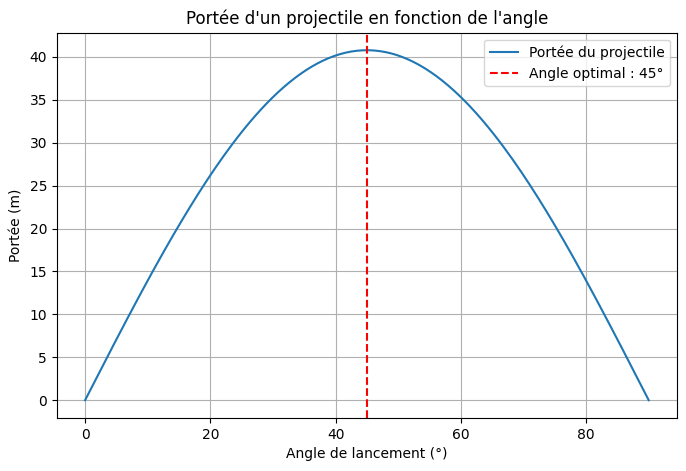

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Définition des symboles
t, v0, g = sym.symbols('t v_0 g', positive=True)
theta = sym.Symbol('theta', positive=True)

# 2. Équations du mouvement
xt = v0 * sym.cos(theta) * t
yt = v0 * sym.sin(theta) * t - g * t**2 / 2

# 3. Temps de vol
solutions_t = sym.solve(yt, t)
tv = [s for s in solutions_t if s != 0][0]

print("Temps de vol :")
display(tv)

# 4. Portée du projectile
P = sym.trigsimp(xt.subs(t, tv))

print("Portée :")
display(P)

# 5. Recherche de l'angle optimal
dP = sym.diff(P, theta)
angles_critiques = sym.solve(dP, theta)

print("Angles critiques :")
display(angles_critiques)

# 6. Conversion en fonction numérique
P_num = sym.lambdify(
    theta,
    P.subs({v0: 20, g: 9.81}),
    'numpy'
)

# 7. Tracé de la portée
angles = np.linspace(0, np.pi / 2, 200)

plt.figure(figsize=(8, 5))
plt.plot(
    np.degrees(angles),
    P_num(angles),
    label="Portée du projectile"
)

plt.axvline(
    45, color="red", linestyle="--",
    label="Angle optimal : 45°"
)

plt.xlabel("Angle de lancement (°)")
plt.ylabel("Portée (m)")
plt.title("Portée d'un projectile en fonction de l'angle")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#@title Solution { display-mode: "form" }
t, v0, g = sym.symbols('t v_0 g', positive=True)
theta = sym.Symbol('theta', positive=True)

xt = v0 * sym.cos(theta) * t
yt = v0 * sym.sin(theta) * t - g * t**2 / 2

tv = sym.solve(yt, t)                 # solutions : t = 0 et t = 2 v0 sin(theta)/g
tv = [s for s in tv if s != 0][0]
P = sym.simplify(xt.subs(t, tv))
display(tv)
display(P)                            # v0^2 sin(2 theta)/g (sous forme équivalente)

dP = sym.diff(P, theta)
display(sym.solve(dP, theta))         # pi/4 : 45°

P_num = sym.lambdify(theta, P.subs({v0: 20, g: 9.81}), 'numpy')
ang = np.linspace(0, np.pi / 2, 200)
plt.plot(np.degrees(ang), P_num(ang))
plt.xlabel("angle (°)"); plt.ylabel("portée (m)")
plt.show()

# Pour aller plus loin

- La [documentation de SymPy](https://docs.sympy.org) et son [tutoriel](https://docs.sympy.org/latest/tutorials/intro-tutorial/index.html) (en anglais).
- Le sous-module `sympy.physics` : mécanique, optique, unités physiques, mécanique quantique…
- **SymPy Gamma / SymPy Live** : essayer SymPy en ligne.

---

*Fin du carnet 6. Vous avez maintenant les bases de Python scientifique pour la physique !*